# Data Mining Lab Assignment 2: Book Recommender System using a Medallion Data Lake

- **Name:** Mayank Mishra  
- **Roll Number:** LCS2023047  
- **Dataset:** Book-Crossing (`BX-Users.csv`, `BX-Books.csv`, `BX-Book-Ratings.csv`)  
- **Architecture:** Bronze -> Silver -> Gold Medallion Data Lake + Item-Based Collaborative Filtering

## Setup: Environment & Output Layer Folders

In [1]:
import os
import html
import tempfile
import urllib.request
import zipfile
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid")

OUTPUT_DIR = "output"
BRONZE_DIR = os.path.join(OUTPUT_DIR, "bronze")
SILVER_DIR = os.path.join(OUTPUT_DIR, "silver")
GOLD_DIR = os.path.join(OUTPUT_DIR, "gold")

for folder in (BRONZE_DIR, SILVER_DIR, GOLD_DIR):
    os.makedirs(folder, exist_ok=True)

print("Medallion output folders ready:", [BRONZE_DIR, SILVER_DIR, GOLD_DIR])

Medallion output folders ready: ['output\\bronze', 'output\\silver', 'output\\gold']


## Step 1: Set Up the Data Lake and Build the Bronze Layer

- Download the raw Book-Crossing ZIP archive and extract the three semicolon-separated, `latin-1` encoded CSV files into a temporary directory without modifying any raw values.
- Load all three tables exactly as they are (`escapechar='\\'` is used for `BX-Books.csv` so backslash-escaped quotes in book titles do not drop rows).
- Append an `ingestion_timestamp` column to each table and persist them to `output/bronze/` as Parquet files with **no cleaning**.

In [2]:
DATASET_URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
RAW_CACHE_DIR = os.path.join(tempfile.gettempdir(), "book_crossings_raw")
os.makedirs(RAW_CACHE_DIR, exist_ok=True)

zip_path = os.path.join(RAW_CACHE_DIR, "book-crossings.zip")
required_csvs = ("BX-Users.csv", "BX-Books.csv", "BX-Book-Ratings.csv")

if not all(os.path.exists(os.path.join(RAW_CACHE_DIR, f)) for f in required_csvs):
    print(f"Downloading dataset from {DATASET_URL} ...")
    urllib.request.urlretrieve(DATASET_URL, zip_path)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(RAW_CACHE_DIR)
    print("Download and extraction complete.")
else:
    print("Using cached raw CSV files in:", RAW_CACHE_DIR)

bronze_users = pd.read_csv(
    os.path.join(RAW_CACHE_DIR, "BX-Users.csv"),
    sep=";",
    encoding="latin-1",
    low_memory=False,
)
bronze_books = pd.read_csv(
    os.path.join(RAW_CACHE_DIR, "BX-Books.csv"),
    sep=";",
    encoding="latin-1",
    escapechar="\\",
    low_memory=False,
)
bronze_ratings = pd.read_csv(
    os.path.join(RAW_CACHE_DIR, "BX-Book-Ratings.csv"),
    sep=";",
    encoding="latin-1",
    low_memory=False,
)

ingestion_ts = datetime.now(timezone.utc).isoformat()
for df in (bronze_users, bronze_books, bronze_ratings):
    df["ingestion_timestamp"] = ingestion_ts

bronze_users.to_parquet(os.path.join(BRONZE_DIR, "users.parquet"), index=False)
bronze_books.to_parquet(os.path.join(BRONZE_DIR, "books.parquet"), index=False)
bronze_ratings.to_parquet(os.path.join(BRONZE_DIR, "ratings.parquet"), index=False)

print("Bronze layer saved successfully:")
for fname in ("users.parquet", "books.parquet", "ratings.parquet"):
    fpath = os.path.join(BRONZE_DIR, fname)
    size_mb = os.path.getsize(fpath) / (1024 * 1024)
    print(f"  {fpath}: {size_mb:.2f} MB")

Using cached raw CSV files in: C:\Users\mayma\AppData\Local\Temp\book_crossings_raw


Bronze layer saved successfully:
  output\bronze\users.parquet: 4.15 MB
  output\bronze\books.parquet: 20.67 MB
  output\bronze\ratings.parquet: 9.36 MB


## Step 2: Explore the Bronze Data (EDA)

Read back the Parquet tables from `output/bronze/` and inspect each required dimension. Under each section, we summarize what we found and what we will do about it in Silver.

In [3]:
b_users = pd.read_parquet(os.path.join(BRONZE_DIR, "users.parquet"))
b_books = pd.read_parquet(os.path.join(BRONZE_DIR, "books.parquet"))
b_ratings = pd.read_parquet(os.path.join(BRONZE_DIR, "ratings.parquet"))
print("Bronze Parquet tables reloaded successfully.")

Bronze Parquet tables reloaded successfully.


### 2.1 Shape, Data Types, and Missing-Value Counts

In [4]:
for name, df in [("Users", b_users), ("Books", b_books), ("Ratings", b_ratings)]:
    print(f"=== {name} ===")
    print(f"Shape: {df.shape}")
    summary = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(4),
    })
    display(summary)
    print(f"Exact duplicate rows: {df.duplicated().sum()}\n")

=== Users ===
Shape: (278858, 4)


,dtype,missing_count,missing_pct
User-ID,int64,0,0.0000
Location,str,0,0.0000
Age,float64,110762,39.7199
ingestion_timestamp,str,0,0.0000


Exact duplicate rows: 0

=== Books ===
Shape: (271379, 9)


,dtype,missing_count,missing_pct
ISBN,str,0,0.0000
Book-Title,str,0,0.0000
Book-Author,str,2,0.0007
Year-Of-Publication,int64,0,0.0000
Publisher,str,2,0.0007
Image-URL-S,str,0,0.0000
Image-URL-M,str,0,0.0000
Image-URL-L,str,0,0.0000
ingestion_timestamp,str,0,0.0000


Exact duplicate rows: 0

=== Ratings ===
Shape: (1149780, 4)


,dtype,missing_count,missing_pct
User-ID,int64,0,0.0
ISBN,str,0,0.0
Book-Rating,int64,0,0.0
ingestion_timestamp,str,0,0.0


Exact duplicate rows: 0



> **Finding & Silver Plan (Shape, Types & Missing Values):** `Users` (278,858 rows) has 110,762 missing `Age` values (39.72%), `Books` (271,379 rows) has 2 missing authors and 2 missing publishers (and 0 missing `Image-URL-*`), and `Ratings` (1,149,780 rows) has no nulls; in Silver we will impute missing/invalid ages with the valid median, drop the unneeded `Image-URL-*` columns, and deduplicate after text standardization.

### 2.2 Distribution of Ratings

Total ratings: 1,149,780
Zero (implicit) ratings: 716,109 (62.28%)
Explicit ratings (1-10): 433,671 (37.72%)


,count,pct
Book-Rating,,
0,716109,62.28
1,1770,0.15
2,2759,0.24
3,5996,0.52
4,8904,0.77
5,50974,4.43
6,36924,3.21
7,76457,6.65
8,103736,9.02


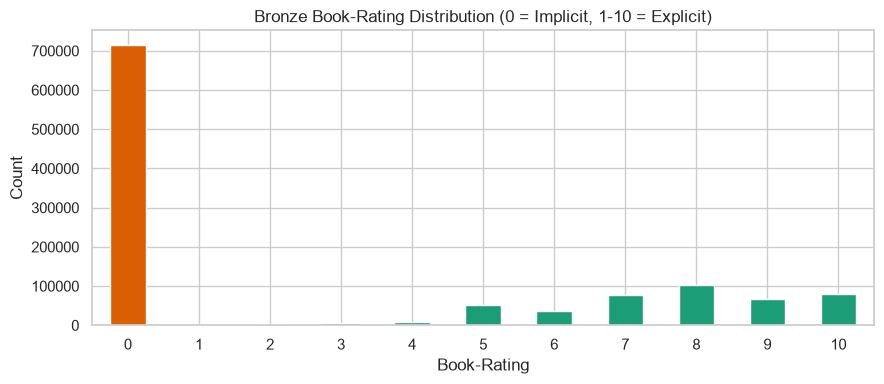

In [5]:
rating_counts = b_ratings["Book-Rating"].value_counts().sort_index()
zero_count = int(rating_counts.get(0, 0))
zero_pct = zero_count / len(b_ratings) * 100
explicit_count = len(b_ratings) - zero_count

print(f"Total ratings: {len(b_ratings):,}")
print(f"Zero (implicit) ratings: {zero_count:,} ({zero_pct:.2f}%)")
print(f"Explicit ratings (1-10): {explicit_count:,} ({100 - zero_pct:.2f}%)")
display(rating_counts.to_frame(name="count").assign(pct=lambda d: (d["count"] / len(b_ratings) * 100).round(2)))

fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#d95f02" if idx == 0 else "#1b9e77" for idx in rating_counts.index]
rating_counts.plot(kind="bar", color=colors, ax=ax)
ax.set_title("Bronze Book-Rating Distribution (0 = Implicit, 1-10 = Explicit)")
ax.set_xlabel("Book-Rating")
ax.set_ylabel("Count")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

> **Finding & Silver Plan (Rating Distribution):** Out of 1,149,780 ratings, 716,109 (62.28%) are `0` (implicit interactions rather than explicit preference scores), while explicit ratings (1–10) skew toward 7–10; in Silver we will remove all `0` ratings and retain only explicit ratings from 1 to 10.

### 2.3 Distribution of User Ages and Publication Years

=== User Ages ===
Non-null ages: 168,096, Missing: 110,762
Min: 0.0, Max: 244.0, Valid median (5-100): 32.0
Impossible ages (< 5): 882 | (> 100): 366

=== Publication Years ===
Non-numeric: 0
Year == 0: 4,619 | Future years (> 2026): 11
Sample future years: {2030: 7, 2050: 2, 2038: 1, 2037: 1}


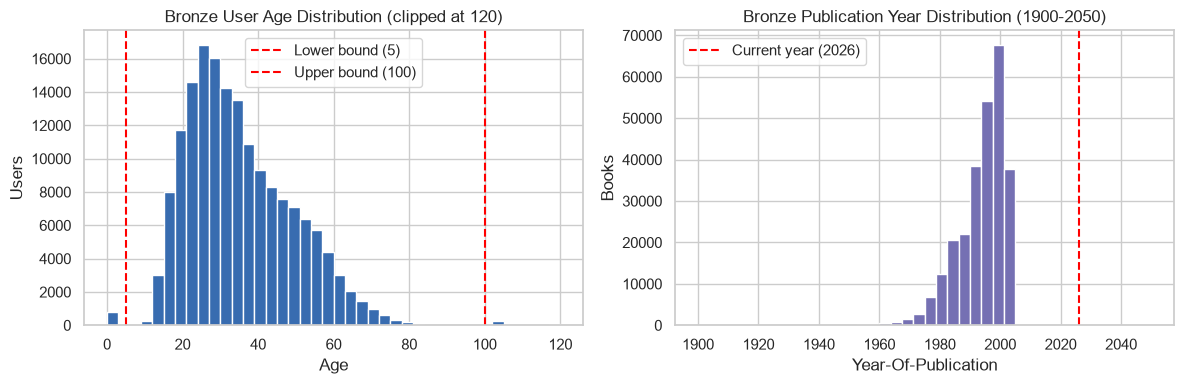

In [6]:
ages_num = pd.to_numeric(b_users["Age"], errors="coerce")
invalid_age_low = int((ages_num < 5).sum())
invalid_age_high = int((ages_num > 100).sum())
valid_ages = ages_num[(ages_num >= 5) & (ages_num <= 100)]

print("=== User Ages ===")
print(f"Non-null ages: {ages_num.notna().sum():,}, Missing: {ages_num.isna().sum():,}")
print(f"Min: {ages_num.min()}, Max: {ages_num.max()}, Valid median (5-100): {valid_ages.median()}")
print(f"Impossible ages (< 5): {invalid_age_low:,} | (> 100): {invalid_age_high:,}")

years_num = pd.to_numeric(b_books["Year-Of-Publication"], errors="coerce")
current_year = datetime.now().year
non_numeric_years = int(years_num.isna().sum())
zero_years = int((years_num == 0).sum())
future_years = int((years_num > current_year).sum())

print("\n=== Publication Years ===")
print(f"Non-numeric: {non_numeric_years}")
print(f"Year == 0: {zero_years:,} | Future years (> {current_year}): {future_years:,}")
print("Sample future years:", b_books.loc[years_num > current_year, "Year-Of-Publication"].value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(ages_num.dropna().clip(upper=120), bins=40, color="#386cb0", edgecolor="white")
axes[0].axvline(5, color="red", linestyle="--", label="Lower bound (5)")
axes[0].axvline(100, color="red", linestyle="--", label="Upper bound (100)")
axes[0].set_title("Bronze User Age Distribution (clipped at 120)")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Users")
axes[0].legend()

valid_plot_years = years_num[(years_num >= 1900) & (years_num <= 2050)]
axes[1].hist(valid_plot_years, bins=40, color="#7570b3", edgecolor="white")
axes[1].axvline(current_year, color="red", linestyle="--", label=f"Current year ({current_year})")
axes[1].set_title("Bronze Publication Year Distribution (1900-2050)")
axes[1].set_xlabel("Year-Of-Publication")
axes[1].set_ylabel("Books")
axes[1].legend()

plt.tight_layout()
plt.show()

> **Finding & Silver Plan (User Ages & Publication Years):** `Users` contains 1,248 impossible ages (882 below 5 and 366 above 100, ranging from 0 to 244) alongside 110,762 missing ages, while `Books` has 4,619 `Year-Of-Publication == 0` and 11 future years up to 2050; in Silver we will set ages `< 5` or `> 100` to null and impute all null ages with the valid median (32), and set `0` or future publication years to null.

### 2.4 Number of Ratings per User and per Book

,Ratings per User,Ratings per Book
count,105283.00,340556.00
mean,10.92,3.38
std,90.56,12.44
min,1.00,1.00
50%,1.00,1.00
75%,4.00,2.00
90%,12.00,6.00
99%,174.00,36.00
max,13602.00,2502.00


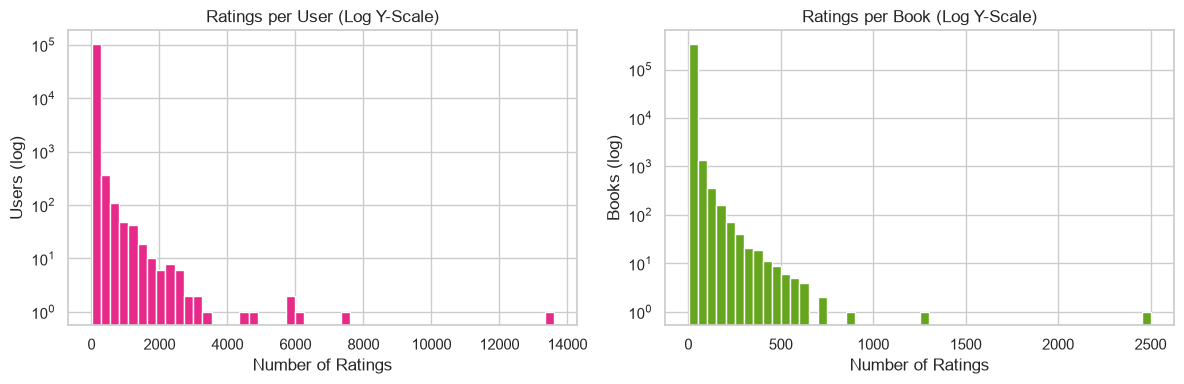

In [7]:
user_rating_counts = b_ratings.groupby("User-ID").size()
book_rating_counts = b_ratings.groupby("ISBN").size()

stats_df = pd.DataFrame({
    "Ratings per User": user_rating_counts.describe(percentiles=[0.5, 0.75, 0.9, 0.99]),
    "Ratings per Book": book_rating_counts.describe(percentiles=[0.5, 0.75, 0.9, 0.99]),
}).round(2)
display(stats_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(user_rating_counts, bins=50, log=True, color="#e7298a", edgecolor="white")
axes[0].set_title("Ratings per User (Log Y-Scale)")
axes[0].set_xlabel("Number of Ratings")
axes[0].set_ylabel("Users (log)")

axes[1].hist(book_rating_counts, bins=50, log=True, color="#66a61e", edgecolor="white")
axes[1].set_title("Ratings per Book (Log Y-Scale)")
axes[1].set_xlabel("Number of Ratings")
axes[1].set_ylabel("Books (log)")

plt.tight_layout()
plt.show()

> **Finding & Silver Plan (Ratings per User & per Book):** Interaction counts are heavily long-tailed—the median user and median book each have only 1 rating (75% of users have <= 4 ratings and 75% of books have <= 2 ratings); in Silver we will filter to users and books with at least 10 explicit ratings so collaborative similarity has reliable overlap.

### 2.5 Matrix Sparsity

In [8]:
n_unique_users = b_ratings["User-ID"].nunique()
n_unique_books = b_ratings["ISBN"].nunique()
total_possible_pairs = n_unique_users * n_unique_books
observed_ratings = len(b_ratings)
density_pct = (observed_ratings / total_possible_pairs) * 100
sparsity_pct = 100.0 - density_pct

print(f"Unique Users in Ratings: {n_unique_users:,}")
print(f"Unique Books in Ratings: {n_unique_books:,}")
print(f"Total Possible User-Book Pairs: {total_possible_pairs:,}")
print(f"Observed Ratings: {observed_ratings:,}")
print(f"Matrix Density: {density_pct:.6f}%")
print(f"Matrix Sparsity: {sparsity_pct:.6f}%")

Unique Users in Ratings: 105,283
Unique Books in Ratings: 340,556
Total Possible User-Book Pairs: 35,854,757,348
Observed Ratings: 1,149,780
Matrix Density: 0.003207%
Matrix Sparsity: 99.996793%


> **Finding & Silver Plan (Matrix Sparsity):** Only 0.003207% of the 35.85 billion possible user-book pairs have a rating (99.996793% sparse); in Silver we will restrict to active users/books (>= 10 explicit ratings) to boost density and in Gold we will store the matrix as a `scipy.sparse` CSR matrix.

## Step 3: Clean the Data and Build the Silver Layer

We apply all required cleaning rules and write the resulting tables to `output/silver/`:
1. Remove duplicate rows across users, books, and ratings (both raw exact duplicates and post-normalization key duplicates).
2. Remove `0` ratings and keep only explicit ratings in `[1, 10]`.
3. Clean user ages: set `< 5` or `> 100` to null, then fill nulls with the valid median age.
4. Split `Location` into `city`, `state`, and `country` columns.
5. Fix publication years: parse numeric years and set `0`, non-numeric, or future years (`> current_year`) to null.
6. Clean text columns (`html.unescape`, collapse/strip whitespace, standardize case) and drop `Image-URL-S`, `Image-URL-M`, `Image-URL-L`.
7. Keep only ratings whose `User-ID` and `ISBN` exist in `users` and `books`.
8. **Minimum rating threshold = 10** (applied iteratively until convergence): from Step 2 EDA, 75%+ of users and books have <= 4 and <= 2 ratings respectively, making the raw matrix 99.9968% sparse. Requiring at least 10 explicit ratings per user and per book removes single-rating noise while preserving a dense, high-signal core of thousands of ratings for reliable item-item cosine similarity.

In [9]:
def clean_text_series(series: pd.Series, case: str = "title") -> pd.Series:
    cleaned = (
        series.astype("string")
        .map(lambda v: html.unescape(v) if pd.notna(v) else pd.NA, na_action="ignore")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )
    cleaned = cleaned.replace("", pd.NA)
    if case == "title":
        return cleaned.str.title()
    if case == "upper":
        return cleaned.str.upper()
    if case == "lower":
        return cleaned.str.lower()
    return cleaned


def parse_location_components(loc_series: pd.Series) -> pd.DataFrame:
    cities, states, countries = [], [], []
    for raw in loc_series:
        if pd.isna(raw):
            cities.append(pd.NA)
            states.append(pd.NA)
            countries.append(pd.NA)
            continue
        parts = [p.strip() for p in str(raw).split(",")]
        if len(parts) >= 3:
            country = parts[-1]
            state = parts[-2]
            city = ", ".join(p for p in parts[:-2] if p)
        elif len(parts) == 2:
            city, state, country = parts[0], parts[1], ""
        else:
            city, state, country = parts[0], "", ""

        cities.append(city if city and city.lower() != "n/a" else pd.NA)
        states.append(state if state and state.lower() != "n/a" else pd.NA)
        countries.append(country if country and country.lower() != "n/a" else pd.NA)

    return pd.DataFrame({"city": cities, "state": states, "country": countries})


silver_users = b_users.drop(columns=["ingestion_timestamp"]).drop_duplicates().copy()
silver_books = b_books.drop(columns=["ingestion_timestamp"]).drop_duplicates().copy()
silver_ratings = b_ratings.drop(columns=["ingestion_timestamp"]).drop_duplicates().copy()

silver_ratings = silver_ratings[silver_ratings["Book-Rating"].between(1, 10)].copy()

silver_users["Age"] = pd.to_numeric(silver_users["Age"], errors="coerce")
silver_users.loc[(silver_users["Age"] < 5) | (silver_users["Age"] > 100), "Age"] = np.nan
median_age = float(silver_users["Age"].median())
silver_users["Age"] = silver_users["Age"].fillna(median_age).astype(int)
print(f"Filled invalid/missing ages with valid median age: {int(median_age)}")

loc_cols = parse_location_components(silver_users["Location"])
for col in ("city", "state", "country"):
    silver_users[col] = clean_text_series(loc_cols[col], case="title")
silver_users = silver_users.drop(columns=["Location"]).drop_duplicates(subset=["User-ID"], keep="first")

current_year = datetime.now().year
silver_books["Year-Of-Publication"] = pd.to_numeric(silver_books["Year-Of-Publication"], errors="coerce")
silver_books.loc[
    (silver_books["Year-Of-Publication"] <= 0) | (silver_books["Year-Of-Publication"] > current_year),
    "Year-Of-Publication",
] = np.nan
silver_books["Year-Of-Publication"] = silver_books["Year-Of-Publication"].astype("Int64")

silver_books = silver_books.drop(columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"])
silver_books["ISBN"] = clean_text_series(silver_books["ISBN"], case="upper")
silver_books["Book-Title"] = clean_text_series(silver_books["Book-Title"], case="title")
silver_books["Book-Author"] = clean_text_series(silver_books["Book-Author"], case="title")
silver_books["Publisher"] = clean_text_series(silver_books["Publisher"], case="title")
silver_books = silver_books.dropna(subset=["ISBN", "Book-Title"]).drop_duplicates(subset=["ISBN"], keep="first")

silver_ratings["ISBN"] = clean_text_series(silver_ratings["ISBN"], case="upper")
silver_ratings = (
    silver_ratings.dropna(subset=["ISBN"])
    .groupby(["User-ID", "ISBN"], as_index=False)["Book-Rating"]
    .mean()
)

silver_ratings = silver_ratings[
    silver_ratings["User-ID"].isin(silver_users["User-ID"])
    & silver_ratings["ISBN"].isin(silver_books["ISBN"])
].copy()
print(f"Explicit ratings with valid users & books before threshold filter: {len(silver_ratings):,}")

MIN_RATINGS = 10
iteration = 0
while True:
    iteration += 1
    prev_len = len(silver_ratings)
    u_counts = silver_ratings["User-ID"].value_counts()
    silver_ratings = silver_ratings[silver_ratings["User-ID"].isin(u_counts[u_counts >= MIN_RATINGS].index)]
    b_counts = silver_ratings["ISBN"].value_counts()
    silver_ratings = silver_ratings[silver_ratings["ISBN"].isin(b_counts[b_counts >= MIN_RATINGS].index)]
    if len(silver_ratings) == prev_len:
        break

silver_users = silver_users[silver_users["User-ID"].isin(silver_ratings["User-ID"])].sort_values("User-ID").reset_index(drop=True)
silver_books = silver_books[silver_books["ISBN"].isin(silver_ratings["ISBN"])].sort_values("ISBN").reset_index(drop=True)
silver_ratings = silver_ratings.sort_values(["User-ID", "ISBN"]).reset_index(drop=True)

silver_users.to_parquet(os.path.join(SILVER_DIR, "users.parquet"), index=False)
silver_books.to_parquet(os.path.join(SILVER_DIR, "books.parquet"), index=False)
silver_ratings.to_parquet(os.path.join(SILVER_DIR, "ratings.parquet"), index=False)

silver_density = len(silver_ratings) / (len(silver_users) * len(silver_books)) * 100
print(f"Converged in {iteration} iterations (threshold >= {MIN_RATINGS} ratings).")
print(f"Silver Users:   {silver_users.shape}")
print(f"Silver Books:   {silver_books.shape}")
print(f"Silver Ratings: {silver_ratings.shape} (Density: {silver_density:.4f}%)")
display(silver_users.head(3))
display(silver_books.head(3))
display(silver_ratings.head(3))

Filled invalid/missing ages with valid median age: 32


Explicit ratings with valid users & books before threshold filter: 383,853


Converged in 7 iterations (threshold >= 10 ratings).
Silver Users:   (1820, 5)
Silver Books:   (2030, 5)
Silver Ratings: (41469, 3) (Density: 1.1224%)


,User-ID,Age,city,state,country
0,243,32,Arden Hills,Minnesota,Usa
1,254,24,Minneapolis,Minnesota,Usa
2,638,20,San Diego,California,Usa


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher
0,0020199600,Great Gatsby (Reissue),F. Scott Fitzgerald,1988,Scribner Paper Fiction
1,0020442203,"Lion, The Witch And The Wardrobe",C.S. Lewis,1970,Macmillan Publishing Company.
2,002542730X,Politically Correct Bedtime Stories: Modern Tales For Our Life And Times,James Finn Garner,1994,John Wiley & Sons Inc


,User-ID,ISBN,Book-Rating
0,243,0060915544,10.0
1,243,0060977493,7.0
2,243,0316601950,9.0


## Step 4: Build the Gold Layer

From the Silver tables, construct model-ready Gold artifacts and save them to `output/gold/`:
- `user_book_matrix.npz`: Sparse CSR matrix (`users x books`) of explicit ratings.
- `user_lookup.parquet` & `book_lookup.parquet`: Index-aligned lookup tables (`matrix_row_idx` / `matrix_col_idx`, book ID, title, author, etc.).
- `user_aggregates.parquet` & `book_aggregates.parquet`: User-level and book-level rating counts and averages.

In [10]:
s_users = pd.read_parquet(os.path.join(SILVER_DIR, "users.parquet"))
s_books = pd.read_parquet(os.path.join(SILVER_DIR, "books.parquet"))
s_ratings = pd.read_parquet(os.path.join(SILVER_DIR, "ratings.parquet"))

user_lookup = s_users.copy().reset_index(drop=True)
user_lookup["matrix_row_idx"] = np.arange(len(user_lookup))

book_lookup = s_books.copy().reset_index(drop=True)
book_lookup["matrix_col_idx"] = np.arange(len(book_lookup))

user_to_row = dict(zip(user_lookup["User-ID"], user_lookup["matrix_row_idx"]))
book_to_col = dict(zip(book_lookup["ISBN"], book_lookup["matrix_col_idx"]))

row_indices = s_ratings["User-ID"].map(user_to_row).to_numpy()
col_indices = s_ratings["ISBN"].map(book_to_col).to_numpy()
rating_values = s_ratings["Book-Rating"].to_numpy(dtype=np.float32)

user_book_matrix = csr_matrix(
    (rating_values, (row_indices, col_indices)),
    shape=(len(user_lookup), len(book_lookup)),
)

user_aggregates = (
    s_ratings.groupby("User-ID", as_index=False)
    .agg(
        rating_count=("Book-Rating", "count"),
        avg_rating=("Book-Rating", "mean"),
        min_rating=("Book-Rating", "min"),
        max_rating=("Book-Rating", "max"),
    )
    .merge(user_lookup[["User-ID", "Age", "city", "state", "country"]], on="User-ID", how="left")
)
user_aggregates["avg_rating"] = user_aggregates["avg_rating"].round(4)

book_aggregates = (
    s_ratings.groupby("ISBN", as_index=False)
    .agg(
        rating_count=("Book-Rating", "count"),
        avg_rating=("Book-Rating", "mean"),
        min_rating=("Book-Rating", "min"),
        max_rating=("Book-Rating", "max"),
    )
    .merge(book_lookup[["ISBN", "Book-Title", "Book-Author", "Year-Of-Publication"]], on="ISBN", how="left")
    .sort_values(["rating_count", "avg_rating"], ascending=[False, False])
    .reset_index(drop=True)
)
book_aggregates["avg_rating"] = book_aggregates["avg_rating"].round(4)

save_npz(os.path.join(GOLD_DIR, "user_book_matrix.npz"), user_book_matrix)
user_lookup.to_parquet(os.path.join(GOLD_DIR, "user_lookup.parquet"), index=False)
book_lookup.to_parquet(os.path.join(GOLD_DIR, "book_lookup.parquet"), index=False)
user_aggregates.to_parquet(os.path.join(GOLD_DIR, "user_aggregates.parquet"), index=False)
book_aggregates.to_parquet(os.path.join(GOLD_DIR, "book_aggregates.parquet"), index=False)

print(f"Gold sparse matrix shape: {user_book_matrix.shape}, stored non-zeros: {user_book_matrix.nnz:,}")
print("Top 10 most-rated books in Gold:")
display(book_aggregates[["ISBN", "Book-Title", "Book-Author", "rating_count", "avg_rating"]].head(10))

Gold sparse matrix shape: (1820, 2030), stored non-zeros: 41,469
Top 10 most-rated books in Gold:


,ISBN,Book-Title,Book-Author,rating_count,avg_rating
0,0316666343,The Lovely Bones: A Novel,Alice Sebold,223,8.2377
1,0385504209,The Da Vinci Code,Dan Brown,177,8.6102
2,0312195516,The Red Tent (Bestselling Backlist),Anita Diamant,132,8.4924
3,0142001740,The Secret Life Of Bees,Sue Monk Kidd,125,8.6640
4,059035342X,Harry Potter And The Sorcerer'S Stone (Harry Potter (Paperback)),J. K. Rowling,119,9.0420
5,0446672211,Where The Heart Is (Oprah'S Book Club (Paperback)),Billie Letts,115,8.2957
6,0060928336,Divine Secrets Of The Ya-Ya Sisterhood: A Novel,Rebecca Wells,113,8.1239
7,043935806X,Harry Potter And The Order Of The Phoenix (Book 5),J. K. Rowling,111,9.0721
8,0345337662,Interview With The Vampire,Anne Rice,105,7.7143
9,0316601950,The Pilot'S Wife : A Novel,Anita Shreve,101,7.7921


## Step 5: Build the Recommender (Item-Based Collaborative Filtering)

1. Load the sparse rating matrix from `output/gold/user_book_matrix.npz` and transpose it so each row is a book and each column is a user.
2. Fit scikit-learn's `NearestNeighbors(metric='cosine', algorithm='brute')` on the sparse `book x user` matrix.
3. Implement `similar_books(title, n=10)` to retrieve the 10 most similar distinct book titles.
4. Implement `recommend(user_id, n=10)` to examine books the user rated highly, collect similar books, rank by similarity weighted by the user's rating, exclude books already read by the user (by both ISBN and title), and return the top `n` titles.

In [11]:
gold_user_book = load_npz(os.path.join(GOLD_DIR, "user_book_matrix.npz")).tocsr()
gold_book_user = gold_user_book.T.tocsr()

gold_books = pd.read_parquet(os.path.join(GOLD_DIR, "book_lookup.parquet"))
gold_users = pd.read_parquet(os.path.join(GOLD_DIR, "user_lookup.parquet"))
gold_book_agg = pd.read_parquet(os.path.join(GOLD_DIR, "book_aggregates.parquet"))

book_meta = gold_books.merge(
    gold_book_agg[["ISBN", "rating_count", "avg_rating"]],
    on="ISBN",
    how="left",
).sort_values("matrix_col_idx").reset_index(drop=True)
book_meta["title_norm"] = book_meta["Book-Title"].str.lower().str.strip()

user_id_to_row = dict(zip(gold_users["User-ID"], gold_users["matrix_row_idx"]))

nn_model = NearestNeighbors(metric="cosine", algorithm="brute")
nn_model.fit(gold_book_user)

print(f"Fitted NearestNeighbors (cosine) on {gold_book_user.shape[0]:,} books x {gold_book_user.shape[1]:,} users.")


def similar_books(title: str, n: int = 10) -> pd.DataFrame:
    query = title.strip().lower()
    exact_matches = book_meta[book_meta["title_norm"] == query]
    if exact_matches.empty:
        partial_matches = book_meta[book_meta["title_norm"].str.contains(query, regex=False, na=False)]
        if partial_matches.empty:
            raise ValueError(f"No book found matching title: {title!r}")
        seed_row = partial_matches.sort_values("rating_count", ascending=False).iloc[0]
    else:
        seed_row = exact_matches.sort_values("rating_count", ascending=False).iloc[0]

    seed_idx = int(seed_row["matrix_col_idx"])
    seed_title_norm = seed_row["title_norm"]

    k_fetch = min(gold_book_user.shape[0], n * 5 + 10)
    distances, indices = nn_model.kneighbors(gold_book_user[seed_idx], n_neighbors=k_fetch)

    seen_titles = {seed_title_norm}
    results = []
    for dist, idx in zip(distances[0], indices[0]):
        if idx == seed_idx:
            continue
        candidate = book_meta.iloc[idx]
        norm_t = candidate["title_norm"]
        if norm_t in seen_titles:
            continue
        seen_titles.add(norm_t)
        results.append({
            "ISBN": candidate["ISBN"],
            "Book-Title": candidate["Book-Title"],
            "Book-Author": candidate["Book-Author"],
            "Cosine-Similarity": round(float(1.0 - dist), 4),
            "Avg-Rating": candidate["avg_rating"],
            "Rating-Count": int(candidate["rating_count"]),
        })
        if len(results) >= n:
            break

    return pd.DataFrame(results)


def get_user_ratings_df(user_id: int) -> pd.DataFrame:
    if user_id not in user_id_to_row:
        raise ValueError(f"User-ID {user_id} not found in Gold layer.")
    row_idx = user_id_to_row[user_id]
    user_row = gold_user_book.getrow(row_idx)
    rated_cols = user_row.indices
    rated_vals = user_row.data
    df = book_meta.iloc[rated_cols][["matrix_col_idx", "ISBN", "Book-Title", "Book-Author", "title_norm"]].copy()
    df["User-Rating"] = rated_vals
    return df.sort_values(["User-Rating", "Book-Title"], ascending=[False, True]).reset_index(drop=True)


def recommend(user_id: int, n: int = 10, high_rating_threshold: float = 7.0, neighbors_per_book: int = 25) -> pd.DataFrame:
    user_df = get_user_ratings_df(user_id)
    read_isbns = set(user_df["ISBN"])
    read_titles = set(user_df["title_norm"])

    liked_df = user_df[user_df["User-Rating"] >= high_rating_threshold]
    if liked_df.empty:
        liked_df = user_df[user_df["User-Rating"] >= user_df["User-Rating"].mean()]

    scores = {}
    for _, row in liked_df.iterrows():
        b_idx = int(row["matrix_col_idx"])
        u_rating = float(row["User-Rating"])
        k_fetch = min(gold_book_user.shape[0], neighbors_per_book + 1)
        distances, indices = nn_model.kneighbors(gold_book_user[b_idx], n_neighbors=k_fetch)

        for dist, nbr_idx in zip(distances[0], indices[0]):
            sim = float(1.0 - dist)
            if sim <= 0:
                continue
            cand = book_meta.iloc[nbr_idx]
            if cand["ISBN"] in read_isbns or cand["title_norm"] in read_titles:
                continue
            title_key = cand["title_norm"]
            weighted_sim = sim * u_rating
            if title_key not in scores:
                scores[title_key] = {
                    "ISBN": cand["ISBN"],
                    "Book-Title": cand["Book-Title"],
                    "Book-Author": cand["Book-Author"],
                    "Weighted-Score": 0.0,
                    "Avg-Rating": cand["avg_rating"],
                    "Rating-Count": int(cand["rating_count"]),
                }
            scores[title_key]["Weighted-Score"] += weighted_sim

    ranked = sorted(scores.values(), key=lambda x: x["Weighted-Score"], reverse=True)[:n]
    rec_df = pd.DataFrame(ranked)
    if not rec_df.empty:
        rec_df["Weighted-Score"] = rec_df["Weighted-Score"].round(4)
    return rec_df

Fitted NearestNeighbors (cosine) on 2,030 books x 1,820 users.


## Step 6: Demo and Sanity Check

First verify `similar_books()` on two popular titles, then run `recommend(user_id, n=10)` for three different users and display each user's highly rated books side-by-side next to their top recommendations.

In [12]:
assert gold_user_book.getnnz(axis=0).min() >= MIN_RATINGS, "Every Gold book must have >= MIN_RATINGS"
assert gold_user_book.getnnz(axis=1).min() >= MIN_RATINGS, "Every Gold user must have >= MIN_RATINGS"

print("=== Item-to-Item Similarity Check: 'The Lovely Bones: A Novel' ===")
display(similar_books("The Lovely Bones: A Novel"))

hp_title = "Harry Potter And The Sorcerer'S Stone (Book 1)"
print(f"\n=== Item-to-Item Similarity Check: {hp_title!r} ===")
display(similar_books(hp_title))

=== Item-to-Item Similarity Check: 'The Lovely Bones: A Novel' ===


,ISBN,Book-Title,Book-Author,Cosine-Similarity,Avg-Rating,Rating-Count
0,0446672211,Where The Heart Is (Oprah'S Book Club (Paperback)),Billie Letts,0.2192,8.2957,115
1,0316096199,Lucky : A Memoir,Alice Sebold,0.2180,8.4737,57
2,0385504209,The Da Vinci Code,Dan Brown,0.1783,8.6102,177
3,0316601950,The Pilot'S Wife : A Novel,Anita Shreve,0.1763,7.7921,101
4,0743418174,Good In Bed,Jennifer Weiner,0.1758,8.0505,99
5,0446531332,Nights In Rodanthe,Nicholas Sparks,0.1702,7.9091,33
6,0688170528,The Pact: A Love Story,Jodi Picoult,0.1682,8.3043,23
7,0316603287,The Lake House,James Patterson,0.1662,7.1852,27
8,0684857820,Lucky,Alice Sebold,0.1651,8.5500,20
9,0316284955,White Oleander : A Novel (Oprah'S Book Club),Janet Fitch,0.1542,8.0377,53



=== Item-to-Item Similarity Check: "Harry Potter And The Sorcerer'S Stone (Book 1)" ===


,ISBN,Book-Title,Book-Author,Cosine-Similarity,Avg-Rating,Rating-Count
0,0439064864,Harry Potter And The Chamber Of Secrets (Book 2),J. K. Rowling,0.6689,8.9625,80
1,0439136350,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,0.6025,9.2892,83
2,0439139597,Harry Potter And The Goblet Of Fire (Book 4),J. K. Rowling,0.4644,9.3590,78
3,043935806X,Harry Potter And The Order Of The Phoenix (Book 5),J. K. Rowling,0.3607,9.0721,111
4,0618002219,The Hobbit: Or There And Back Again,J.R.R. Tolkien,0.2328,8.9524,21
5,0618002227,"The Fellowship Of The Ring (The Lord Of The Rings, Part 1)",J. R. R. Tolkien,0.1905,9.0000,29
6,0064471047,"The Lion, The Witch, And The Wardrobe (The Chronicles Of Narnia, Book 2)",C. S. Lewis,0.1567,8.9630,27
7,0880381736,"Dragons Of Autumn Twilight (Dragonlance Chronicles, Vol 1)",Margaret Weis,0.1557,8.6000,10
8,0316769487,The Catcher In The Rye,J.D. Salinger,0.1528,7.7500,88
9,0399146431,The Bonesetter'S Daughter,Amy Tan,0.1500,8.3333,21


In [13]:
demo_users = [254, 638, 882]

for uid in demo_users:
    user_info = gold_users[gold_users["User-ID"] == uid].iloc[0]
    user_history = get_user_ratings_df(uid)
    highly_rated = (
        user_history[user_history["User-Rating"] >= 8][["Book-Title", "Book-Author", "User-Rating"]]
        .head(10)
        .reset_index(drop=True)
    )
    highly_rated.columns = ["Highly Rated Title", "Liked Author", "User Rating"]

    recs = recommend(uid, n=10).reset_index(drop=True)
    assert len(recs) == 10
    assert recs["Weighted-Score"].is_monotonic_decreasing
    assert set(recs["Book-Title"].str.lower().str.strip()).isdisjoint(set(user_history["title_norm"]))

    recs_view = recs[["Book-Title", "Book-Author", "Weighted-Score", "Avg-Rating"]].copy()
    recs_view.columns = ["Recommended Title", "Rec Author", "Weighted Score", "Avg Rating"]

    print("=" * 100)
    print(
        f"USER {uid} | Age: {user_info['Age']} | Location: "
        f"{user_info['city']}, {user_info['state']}, {user_info['country']} | "
        f"Total Gold Ratings: {len(user_history)}"
    )
    display(pd.concat([highly_rated, recs_view], axis=1))

USER 254 | Age: 24 | Location: Minneapolis, Minnesota, Usa | Total Gold Ratings: 20


,Highly Rated Title,Liked Author,User Rating,Recommended Title,Rec Author,Weighted Score,Avg Rating
0,American Gods,Neil Gaiman,10.0,Harry Potter And The Order Of The Phoenix (Book 5),J. K. Rowling,19.1690,9.0721
1,1984,George Orwell,9.0,"The Return Of The King (The Lord Of The Rings, Part 3)",J. R. R. Tolkien,15.8801,9.5833
2,American Gods: A Novel,Neil Gaiman,9.0,Harry Potter And The Sorcerer'S Stone (Harry Potter (Paperback)),J. K. Rowling,12.3574,9.0420
3,Harry Potter And The Chamber Of Secrets (Book 2),J. K. Rowling,9.0,"The Two Towers (The Lord Of The Rings, Part 2)",J. R. R. Tolkien,8.5862,9.9333
4,Harry Potter And The Chamber Of Secrets (Book 2),J. K. Rowling,9.0,Stardust,Neil Gaiman,8.4577,8.0833
5,Harry Potter And The Goblet Of Fire (Book 4),J. K. Rowling,9.0,Brave New World,Aldous Huxley,7.9437,7.7500
6,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,9.0,"The Amber Spyglass (His Dark Materials, Book 3)",Philip Pullman,6.9248,9.0000
7,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,9.0,The Catcher In The Rye,J.D. Salinger,5.5905,7.7500
8,Harry Potter And The Sorcerer'S Stone (Book 1),J. K. Rowling,9.0,Prodigal Summer,Barbara Kingsolver,5.2910,8.4444
9,Smoke And Mirrors: Short Fictions And Illusions,Neil Gaiman,9.0,Charlotte'S Web (Trophy Newbery),E. B. White,5.1164,9.3448


USER 638 | Age: 20 | Location: San Diego, California, Usa | Total Gold Ratings: 22


,Highly Rated Title,Liked Author,User Rating,Recommended Title,Rec Author,Weighted Score,Avg Rating
0,Barrel Fever : Stories And Essays (Barrel Fever),David Sedaris,10.0,Midnight Bayou,Nora Roberts,15.8796,8.6364
1,Four Blind Mice,James Patterson,10.0,The Wedding,Nicholas Sparks,9.1457,7.7059
2,Me Talk Pretty One Day,David Sedaris,10.0,The Face,Dean Koontz,8.9238,8.4167
3,Message In A Bottle,Nicholas Sparks,10.0,The Conspiracy Club,Jonathan Kellerman,8.8941,7.7500
4,Nights In Rodanthe,Nicholas Sparks,10.0,Gap Creek: The Story Of A Marriage,Robert Morgan,8.8816,7.0000
5,Skipping Christmas,John Grisham,10.0,Dead Aim,Iris Johansen,8.7362,7.1818
6,Suzanne'S Diary For Nicholas,James Patterson,10.0,The Gift,Danielle Steel,7.5705,7.7500
7,The Catcher In The Rye,J.D. Salinger,10.0,Someone To Watch Over Me : A Novel,Judith Mcnaught,6.6684,7.6923
8,The Da Vinci Code,Dan Brown,10.0,The Penwyth Curse,Catherine Coulter,6.6326,5.6000
9,The Guardian,Nicholas Sparks,10.0,Mortal Prey,John Sandford,6.6282,8.1875



USER 882 | Age: 23 | Location: Berkeley, California, Usa | Total Gold Ratings: 17


,Highly Rated Title,Liked Author,User Rating,Recommended Title,Rec Author,Weighted Score,Avg Rating
0,Bridge To Terabithia,Katherine Paterson,10.0,The Valley Of Horses,Jean M. Auel,4.4441,8.0833
1,Eva Luna,Isabel Allende,10.0,The Red Tent (Bestselling Backlist),Anita Diamant,4.3504,8.4924
2,Snow Falling On Cedars,David Guterson,10.0,Night Whispers,Judith Mcnaught,4.2174,7.8667
3,The Alienist,Caleb Carr,10.0,Girl With A Pearl Earring,Tracy Chevalier,4.2031,9.1818
4,The Clan Of The Cave Bear (Earth'S Children (Paperback)),Jean M. Auel,10.0,Holding The Dream (Dream Trilogy),Nora Roberts,4.1294,7.6875
5,The Da Vinci Code,Dan Brown,10.0,Born In Ice,Nora Roberts,4.0562,8.3750
6,The River King,Alice Hoffman,10.0,Daughter Of Fortune : A Novel (Oprah'S Book Club (Hardcover)),Isabel Allende,3.9231,8.3846
7,The Smoke Jumper,Nicholas Evans,10.0,Here On Earth,Alice Hoffman,3.7161,7.1875
8,The Thorn Birds,Colleen Mccullough,10.0,The Plains Of Passage (Earth'S Children (Paperback)),Jean M. Auel,3.5360,7.7600
9,Midnight In The Garden Of Good And Evil: A Savannah Story,John Berendt,9.0,The Copper Beech,Maeve Binchy,3.4687,7.5789
